In [1]:
# imports

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from pathlib import Path


# Bernoulli model
Estimate gene family prevalences (pi values) from incomplete genomes based on a 
Bernoulli model

In [2]:
# function to estimate gene family prevalence using a Bernoulli model

def estimate_prevalence_bernoulli(data, lambdas, clip_max=1.0):
    """
    Estimate gene family prevalence using a Bernoulli model.
    
    Parameters:
    data (pd.DataFrame): A DataFrame containing presence/absence data for gene families across genomes.
    lambdas (pd.Series): A series of lambda values corresponding to the completeness of each genome
        in the dataset, with values between 0 and 1.
    clip_max (float): Maximum value to clip the estimated prevalence (default is 1.0). 
        If set to None, no clipping will be applied.
    
    Returns:
    pd.Series: A series of pi values representing the estimated prevalence of each gene family.
    """
    # Ensure that the index of lambdas matches the columns of data
    if not all(lambdas.index == data.columns):
        raise ValueError("The index of lambdas must match the columns of data.")
    
    # Ensure the presence/absence data is binary (0 and 1)
    data = data.astype(int)  # Convert to integer type if not already
    if not data.map(lambda x: x in [0, 1]).all().all():
        raise ValueError("Data must be binary (0 and 1).")
    
    # Calculate inverse of the lambda values
    inverse_lambdas = 1 / lambdas

    # Multiply the presence/absence data by the inverse of the lambda values
    weighted_data = data.multiply(inverse_lambdas, axis=1)

    # Estimate the prevalence (pi) for each gene family as the expected value of the weighted presence/absence data
    pi_estimates = weighted_data.mean(axis=1)
    
    # Clip the estimated prevalence values if clip_max is specified
    if clip_max is not None:
        pi_estimates = pi_estimates.clip(upper=clip_max)
    
    return pi_estimates

# Simulated Data
Evaluate model using simulated data
- Uniform missingness
- Systematic missingness
- Systematic missingness due to multicopy genes

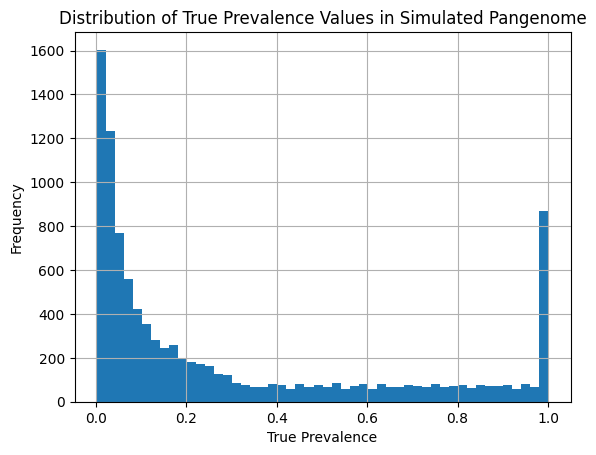

In [3]:
# read in simulated pangenome data

sim_data_dir = Path('../data/simulated')

# simulated presence/absence data
sim_pangenome_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_complete.csv', index_col=0)
sim_incomplete_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_incomplete.csv', index_col=0)
sim_incomplete_biased_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_incomplete_biased.csv', index_col=0)
sim_incomplete_count_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_incomplete_from_count.csv', index_col=0)

# simulated genome completeness values
sim_completeness = pd.read_csv(
    sim_data_dir / 'simulated_genome_completeness_levels.csv', index_col=0)['Completeness']

# simulated detection bias values
sim_detection_bias = pd.read_csv(
    sim_data_dir / 'simulated_gene_detection_bias_values.csv', index_col=0)['Detection_Bias']

# simulated gene count per genome data
sim_mean_gene_count_df = pd.read_csv(
    sim_data_dir / 'simulated_mean_gene_counts_when_present.csv', index_col=0)['Mean_Gene_Count_When_Present']

# calculate ground truth prevalence values for simulated data using complete presence/absence data
ground_truth = sim_pangenome_df.mean(axis=1)
ground_truth.hist(bins=50)
plt.xlabel('True Prevalence')
plt.ylabel('Frequency')
plt.title('Distribution of True Prevalence Values in Simulated Pangenome')
plt.show()


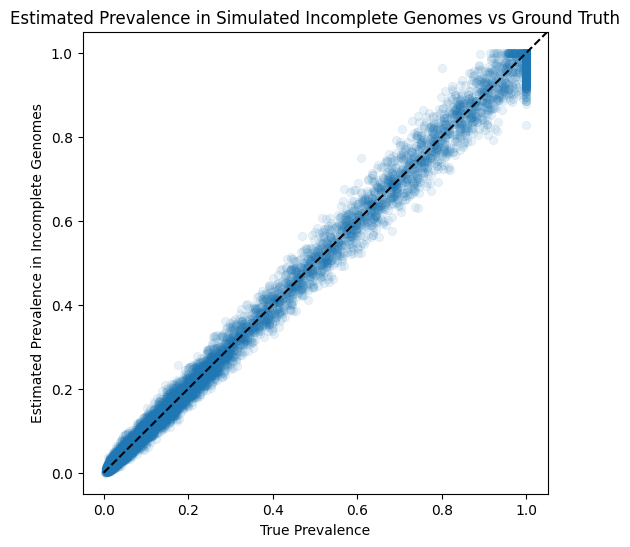

In [4]:
# run Bernoulli model on simulated data with uniform missingness

lambdas_incomplete = estimate_prevalence_bernoulli(
    data=sim_incomplete_df,
    lambdas=sim_completeness.loc[sim_incomplete_df.columns]
)

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(x=ground_truth, y=lambdas_incomplete, alpha=0.1, edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set labels and title
plt.xlabel('True Prevalence')
plt.ylabel('Estimated Prevalence in Incomplete Genomes')
plt.title('Estimated Prevalence in Simulated Incomplete Genomes vs Ground Truth')
plt.show()


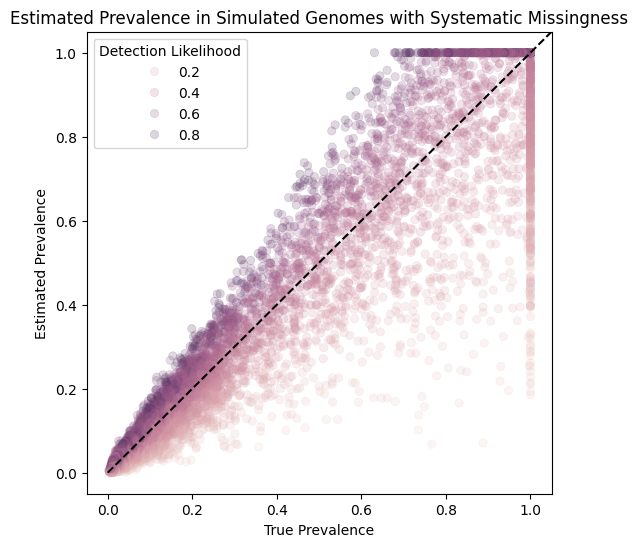

In [5]:
# run Bernoulli model on simulated data with biased missingness

lambdas_incomplete = estimate_prevalence_bernoulli(
    data=sim_incomplete_biased_df,
    lambdas=sim_completeness.loc[sim_incomplete_biased_df.columns]
)

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(
    x=ground_truth, 
    y=lambdas_incomplete, 
    hue=sim_detection_bias.loc[sim_incomplete_biased_df.index],
    alpha=0.2, 
    edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set labels and title
plt.xlabel('True Prevalence')
plt.ylabel('Estimated Prevalence')
plt.title('Estimated Prevalence in Simulated Genomes with Systematic Missingness')
plt.legend(title='Detection Likelihood')

# Show the plot
plt.show()

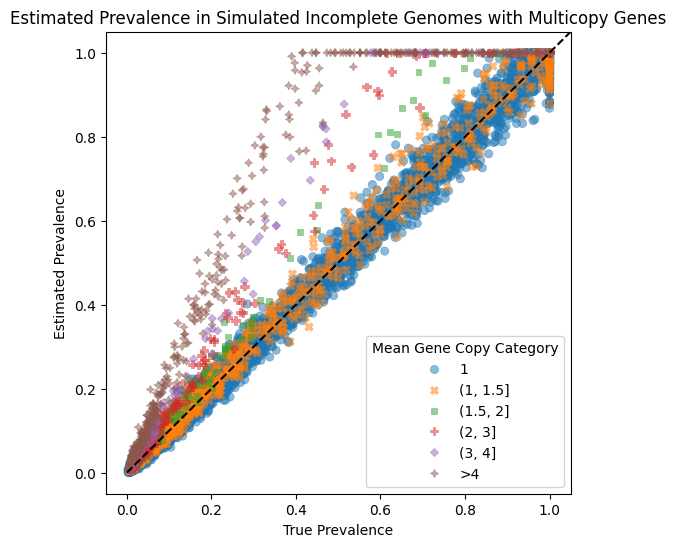

In [6]:
# run Bernoulli model on incomplete simulated data created using multicopy gene counts

lambdas_incomplete = estimate_prevalence_bernoulli(
    data=sim_incomplete_count_df,
    lambdas=sim_completeness.loc[sim_incomplete_count_df.columns]
)

# build categorical variable for mean gene count
mean_gene_count_bins = pd.cut(
    sim_mean_gene_count_df, 
    bins=[0, 1, 1.5, 2, 3, 4, np.inf], 
    labels=['1', '(1, 1.5]', '(1.5, 2]', '(2, 3]', '(3, 4]', '>4'])

# # build categorical variable for mean gene count by rounding to nearest integer
# mean_gene_count_bins = sim_mean_gene_count_df.round().astype(int).astype(str)

# pull together plot data
plot_df = pd.DataFrame({
    'True Prevalence': ground_truth,
    'Estimated Prevalence': lambdas_incomplete,
    'Mean Gene Copy': sim_mean_gene_count_df.loc[sim_incomplete_count_df.index],
    'Mean Gene Copy Category': mean_gene_count_bins.loc[sim_incomplete_count_df.index]
})
plot_df = plot_df.sort_values('Mean Gene Copy')

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(
    # data=plot_df[plot_df['Mean Gene Copy'].lt(3)],  # Filter to only include genes with mean gene copy < 3
    data=plot_df,  # Filter to only include genes with mean gene copy < 3
    x='True Prevalence', 
    y='Estimated Prevalence', 
    hue='Mean Gene Copy Category',
    style='Mean Gene Copy Category',
    alpha=0.5, 
    edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set title and show plot
plt.title('Estimated Prevalence in Simulated Incomplete Genomes with Multicopy Genes')
plt.show()

# Real data
Evaluate model using real data

In [7]:
# read in real data

# full dataset
pa_complete_df = pd.read_csv('../data/subsets/pro_presence_absence_data_complete.csv', index_col=0)
pa_incomplete_df = pd.read_csv('../data/subsets/pro_presence_absence_data_incomplete.csv', index_col=0)
count_complete_df = pd.read_csv('../data/subsets/pro_count_data_complete.csv', index_col=0)
count_incomplete_df = pd.read_csv('../data/subsets/pro_count_data_incomplete.csv', index_col=0)

# subset of real data with balanced representation of complete and incomplete genomes across clades
subset_pa_complete_df = pd.read_csv(
    '../data/subsets/pro_presence_absence_data_complete_clade_balanced.csv', index_col=0)
subset_pa_incomplete_df = pd.read_csv(
    '../data/subsets/pro_presence_absence_data_incomplete_clade_balanced.csv', index_col=0)
subset_count_complete_df = pd.read_csv(
    '../data/subsets/pro_count_data_complete_clade_balanced.csv', index_col=0)
subset_count_incomplete_df = pd.read_csv(
    '../data/subsets/pro_count_data_incomplete_clade_balanced.csv', index_col=0)

# genome and gene family metadata
genome_metadata_df = pd.read_csv('../data/pro_pangenome_metadata.csv')
clade_series = genome_metadata_df.set_index('genome')['clade']
completeness_series = genome_metadata_df.set_index('genome')['completeness'] / 100
mean_gene_count = count_complete_df[count_complete_df > 0].mean(axis=1)
subset_mean_gene_count = subset_count_complete_df[subset_count_complete_df > 0].mean(axis=1)

# determine most represented clade for each gene family in full and subset datasets
clade_sums_full = pd.concat(
    [count_complete_df, count_incomplete_df], axis=1).T.groupby(clade_series).sum().T
most_represented_clade_full = clade_sums_full.idxmax(axis=1)
clade_sums_subset = pd.concat(
    [subset_count_complete_df, subset_count_incomplete_df], axis=1).T.groupby(clade_series).sum().T
most_represented_clade_subset = clade_sums_subset.idxmax(axis=1)
most_represented_clade_subset[clade_sums_subset.max(axis=1) == 0] = 'Not Detected'

most_represented_clade_full.value_counts()

HLII          13683
LLVII          8499
LLI            5931
AMZ-I          5308
AMZ-III        4007
LLII-LLIII     3981
LLIV           3763
HLI            3596
AMZ-II         1736
HLIV           1004
LLVIII          744
HLVI            288
HLIII           251
HLII-HLVI        67
Name: count, dtype: int64

## Clade-Balance Subset

Test model on subset of data in which complete and incomplete genome sets have 
proportional clade compositions.

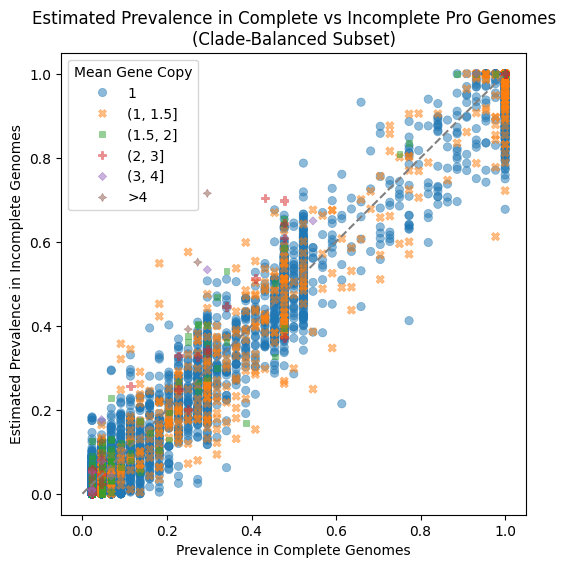

In [8]:
# plot pi estimates against ground truth prevalence values

# calculate pi estimates for incomplete genomes
lambdas_incomplete = estimate_prevalence_bernoulli(
    data=subset_pa_incomplete_df, 
    lambdas=completeness_series.loc[subset_pa_incomplete_df.columns]
)

# calculate "ground truth" prevalence values from complete genomes
ground_truth = subset_pa_complete_df.mean(axis=1).loc[subset_pa_incomplete_df.index]

# build categorical variable for mean gene count
mean_gene_count_bins = pd.cut(
    subset_mean_gene_count, 
    bins=[0, 1, 1.5, 2, 3, 4, np.inf], 
    labels=['1', '(1, 1.5]', '(1.5, 2]', '(2, 3]', '(3, 4]', '>4'])

# pull together plot data
plot_df = pd.DataFrame({
    'Prevalence in Complete Genomes': ground_truth,
    'Estimated Prevalence in Incomplete Genomes': lambdas_incomplete,
    'Mean Gene Copy': mean_gene_count_bins.loc[subset_pa_incomplete_df.index]
})
plot_df = plot_df.sort_values('Mean Gene Copy')

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(
    # data=plot_df[plot_df['Mean Gene Copy'] != '1'],
    data=plot_df,
    x='Prevalence in Complete Genomes', 
    y='Estimated Prevalence in Incomplete Genomes', 
    hue='Mean Gene Copy',
    style='Mean Gene Copy',
    alpha=0.5, 
    edgecolor=None,)

# Add a line for perfect agreement
plt.plot([0, 1], [0, 1], '--', color='gray')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set title and show plot
plt.title('Estimated Prevalence in Complete vs Incomplete Pro Genomes\n(Clade-Balanced Subset)')
plt.show()


## Full Dataset
Full set of complete and incomplete _Prochlorococcus_ genomes (not clade-balanced)

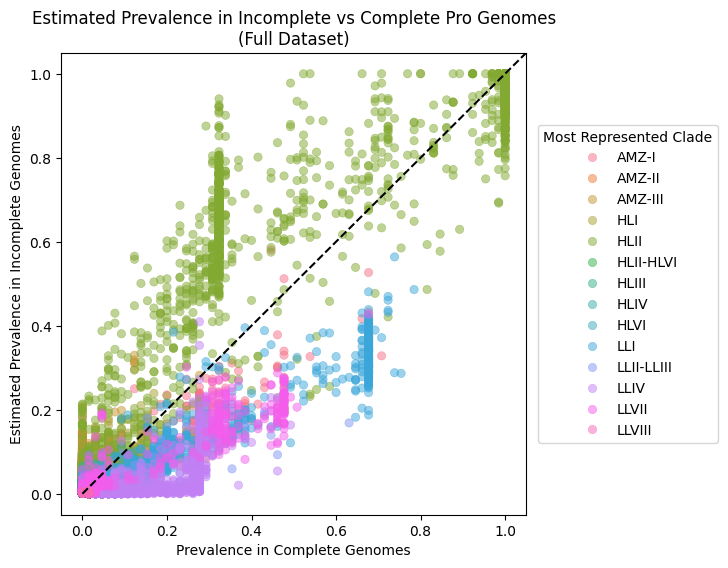

In [9]:
# run Bernoulli model on full set of incomplete genomes and compare to 
# prevalence values in full set of complete genomes

lambdas_incomplete = estimate_prevalence_bernoulli(
    data=pa_incomplete_df,
    lambdas=completeness_series.loc[pa_incomplete_df.columns]
)

# calculate "ground truth" prevalence values from complete genomes
ground_truth = pa_complete_df.mean(axis=1).loc[pa_incomplete_df.index]

# pull together plot data
plot_df = pd.DataFrame({
    'Prevalence in Complete Genomes': ground_truth,
    'Estimated Prevalence in Incomplete Genomes': lambdas_incomplete,
    'Most Represented Clade': most_represented_clade_full.loc[pa_incomplete_df.index],
})
plot_df = plot_df.sort_values('Most Represented Clade')

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(
    data=plot_df,
    x='Prevalence in Complete Genomes', 
    y='Estimated Prevalence in Incomplete Genomes', 
    hue='Most Represented Clade',
    alpha=0.5, 
    edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set title and show plot
plt.title('Estimated Prevalence in Incomplete vs Complete Pro Genomes\n(Full Dataset)')
plt.legend(title='Most Represented Clade', bbox_to_anchor=(1.01, 0.5), loc='center left')
plt.show()

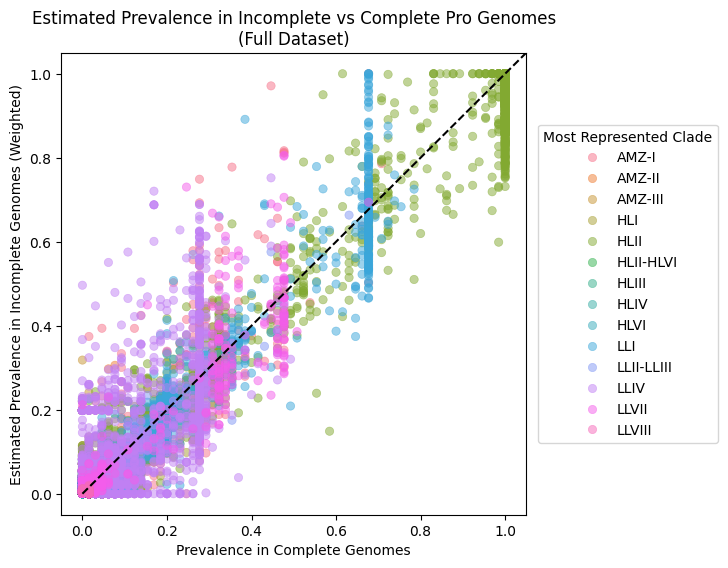

In [10]:
# correct for class imbalance across clades by estimating prevalence separately within
# each clade and then combining results across clades with a weighted average 
# based on the number of complete genomes in each clade

# initializee dataframe to organize data for plotting
plot_df = pd.DataFrame(index=pa_incomplete_df.index)

# calculate prevalence estimates separately within each clade
for clade in clade_series.unique():
    clade_genomes = clade_series[clade_series == clade].index
    clade_incomplete_genomes = pa_incomplete_df.columns.intersection(clade_genomes)
    clade_lambdas_incomplete = estimate_prevalence_bernoulli(
        data=pa_incomplete_df[clade_incomplete_genomes],
        lambdas=completeness_series.loc[clade_incomplete_genomes], 
        clip_max=None
    )
    plot_df[clade] = clade_lambdas_incomplete

# calculate weighted average of prevalence estimates across clades, 
# using the number of complete genomes in each clade as weights
clade_weights = clade_series.loc[pa_complete_df.columns].value_counts()
lambdas_incomplete = plot_df.multiply(clade_weights, axis=1).sum(axis=1) / clade_weights.sum()
lambdas_incomplete = lambdas_incomplete.clip(upper=1.0)  # Clip values to a maximum of 1.0
plot_df['Estimated Prevalence in Incomplete Genomes (Weighted)'] = lambdas_incomplete

# calculate "ground truth" prevalence values from complete genomes
ground_truth = pa_complete_df.mean(axis=1).loc[pa_incomplete_df.index]
plot_df['Prevalence in Complete Genomes'] = ground_truth

# add most represented clade for each gene family to plot_df
plot_df['Most Represented Clade'] = most_represented_clade_full.loc[pa_incomplete_df.index]
plot_df = plot_df.sort_values('Most Represented Clade')

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(
    data=plot_df,
    x='Prevalence in Complete Genomes', 
    y='Estimated Prevalence in Incomplete Genomes (Weighted)', 
    hue='Most Represented Clade',
    alpha=0.5, 
    edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set title and show plot
plt.title('Estimated Prevalence in Incomplete vs Complete Pro Genomes\n(Full Dataset)')
plt.legend(title='Most Represented Clade', bbox_to_anchor=(1.01, 0.5), loc='center left')
plt.show()

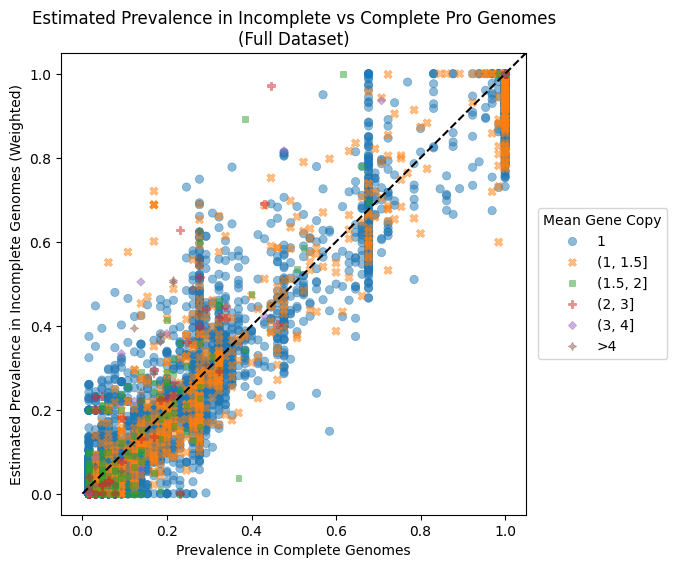

In [11]:
# color by gene copy number in complete genomes instead of most represented clade

# mean gene copy number from complete genomes for each gene family
mean_gene_count_bins = pd.cut(
    mean_gene_count.loc[pa_incomplete_df.index], 
    bins=[0, 1, 1.5, 2, 3, 4, np.inf], 
    labels=['1', '(1, 1.5]', '(1.5, 2]', '(2, 3]', '(3, 4]', '>4'])
plot_df['Mean Gene Copy'] = mean_gene_count_bins.loc[pa_incomplete_df.index]
plot_df = plot_df.sort_values('Mean Gene Copy')

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(
    # data=plot_df[plot_df['Mean Gene Copy'] != '1'],  # Filter to only include genes with mean gene copy > 1
    data= plot_df,
    x='Prevalence in Complete Genomes', 
    y='Estimated Prevalence in Incomplete Genomes (Weighted)', 
    hue='Mean Gene Copy',
    style='Mean Gene Copy',
    alpha=0.5, 
    edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set title and show plot
plt.title('Estimated Prevalence in Incomplete vs Complete Pro Genomes\n(Full Dataset)')
plt.legend(title='Mean Gene Copy', bbox_to_anchor=(1.01, 0.5), loc='center left')
plt.show()